In [30]:
import numpy as np
import matplotlib.pyplot as plt

In [31]:
def f(x):
  return np.sin(x)    # Example Function

In [32]:
def reimann_sum(a, b, n, method='left', discrete_data=None):
  if discrete_data is not None:
    x_points = np.linspace(a, b, len(discrete_data))
    dx = (b-a) / (len(discrete_data)-1)
    if method == 'left':
      x_rect = x_points[:-1]
      y_values = np.array(discrete_data[:-1])
    elif method == 'right':
      x_rect = x_points[1:]
      y_values = np.array(discrete_data[1:])
    elif method == 'midpoint':
      x_rect = (x_points[:-1] + x_points[1:]) / 2
      y_values = np.array(discrete_data[:-1] + np.array(discrete_data[1:])) / 2
    else:
      raise ValueError("Method must be 'left', 'right', or 'midpoint'")
    sum_value = np.sum(y_values * dx)
    return sum_value, x_rect, dx, y_values
  x = np.linspace(a, b, n+1)    # Partition Points
  dx = (b-a) / n                # Width of each rectangle
  if method == 'left':
    x_points = x[:-1]    # Left endpoints
  elif method == 'right':
    x_points = x[1:]    # Right endpoints
  elif method == 'midpoint':
    x_points = (x[:-1] + x[1:]) / 2    # Midpoints
  else:
    raise ValueError("Method must be 'left', 'right', or 'midpoint'")
  sum_value = np.sum(f(x_points) * dx)    # Approximation of integral
  exact_value = -np.cos(b) + np.cos(a)    # Exact integral of sin(x)
  error = abs(exact_value - sum_value)    # Absolute error
  return sum_value, error, x_points, dx

In [33]:
def plot_reimann(a, b, n, method, discrete_data=None):
  if discrete_data is not None:
    sum_value, x_points, dx, y_values = reimann_sum(a, b, n, method, discrete_data)
    plt.figure(figsize=(8, 5))
    plt.scatter(x_points, y_values, color='red', label='Discrete Data')
    plt.bar(x_points, y_values, width=dx, align='edge', alpha=0.4, color='blue', edgecolor='black')
    plt.title(f'Discrete Reimann Sum ({method.capitalize()} Endpoint), n={len(discrete_data)-1}\n Approximate Integral: {sum_value:.5f}')
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()
    plt.show()
    return
  sum_value, error, x_points, dx = reimann_sum(a, b, n, method)
  x = np.linspace(a, b, 1000)
  y = f(x)
  plt.figure(figsize=(8, 5))
  plt.plot(x, y, 'r-', label='f(x) = sin(x)')
  plt.bar(x_points, f(x_points), width=dx, align='edge', alpha=0.4, color='blue', edgecolor='black')
  plt.title(f'Reimann Sum ({method.capitalize()} Endpoint), n={n}\nApproximate Integral: {sum_value:.5f}, Error: {error:.5f}')
  plt.xlabel('x')
  plt.ylabel('f(x)')
  plt.legend()
  plt.show()

In [34]:
# Parameters
a, b = 0, np.pi    # Interval
n = 10             # Number of rectangles

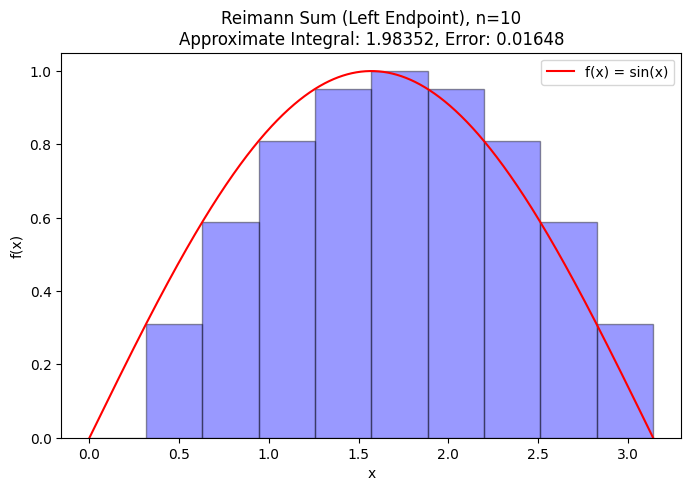

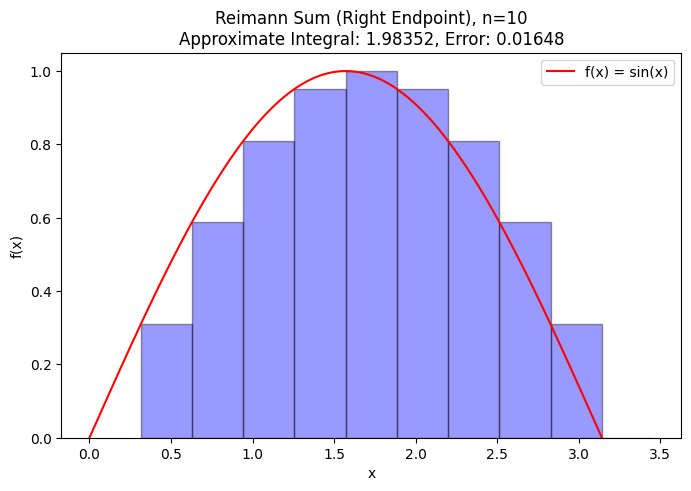

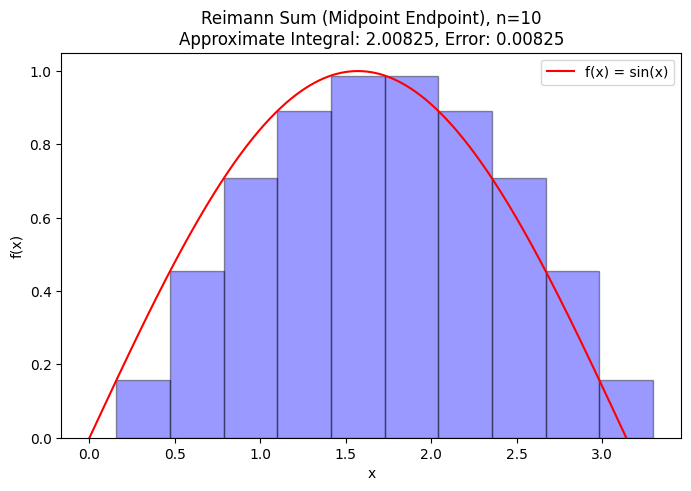

In [35]:
# Plot for different methods
for method in ['left', 'right', 'midpoint']:
  plot_reimann(a, b, n, method)

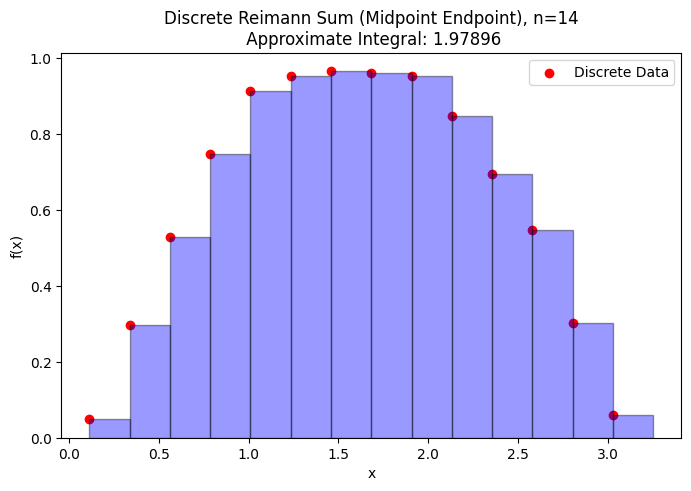

In [36]:
# Example with discrete data
discrete_x = np.linspace(a, b, 15)
discrete_y = np.sin(discrete_x) + np.random.normal(0, 0.05, len(discrete_x))    # Noise sine wave
discrete_data = list(discrete_y)
plot_reimann(a, b, len(discrete_data)-1, 'midpoint', discrete_data=discrete_data)

## Reimann Sum for discrete data

In [37]:
def reimann_sum_discrete(x, y, method='left'):
  """
  Computes the Reimann Sum for discrete data.

  Parameters:
    x: list or numpy array (monotonically increasing values)
    y: list or numpy array (function values at corresponding x values)
    method: str, 'left', 'right', or 'midpoint' (default is 'left')

  Returns:
    float: Approximate integral using the Reimann Sum.
  """
  n = len(x)-1    # Number of subintervals
  reimann_sum = 0.0
  if method == 'left':
    for i in range(n):
      reimann_sum += y[i] * (x[i+1] - x[i])
  elif method == 'right':
    for i in range(n):
      reimann_sum += y[i+1] * (x[i+1] - x[i])
  elif method == 'midpoint':
    for i in range(n):
      mid_x = (x[i] + x[i+1]) / 2
      mid_y = (y[i] + y[i+1]) / 2    # Approximate function value at midpoint
      reimann_sum += mid_y * (x[i+1] - x[i])
  else:
    raise ValueError("Method must be 'left', 'right', or 'midpoint'")
  return reimann_sum

In [38]:
# Example discrete dataset
#-------------- Example-1 --------------
x_values = np.array([0, 1, 2, 3, 4, 5, 6, 7])
y_values = np.array([2, 3, 5, 7, 11, 13, 17, 19])
#-------------- Example-2 --------------
# x_values = np.array([0, 0.2, 0.4, 0.6, 0.8, 1, 1.2])
# y_values = np.array([1, 0.9608, 0.8521, 0.6977, 0.5273, 0.3679, 0.2369])

In [39]:
# Compute Reimann sums for different methods
left_sum = reimann_sum_discrete(x_values, y_values, method='left')
right_sum = reimann_sum_discrete(x_values, y_values, method='right')
midpoint_sum = reimann_sum_discrete(x_values, y_values, method='midpoint')

In [40]:
print(f"Left Reimann Sum: {left_sum}")
print(f"Right Reimann Sum: {right_sum}")
print(f"Midpoint Reimann Sum: {midpoint_sum}")

Left Reimann Sum: 58.0
Right Reimann Sum: 75.0
Midpoint Reimann Sum: 66.5


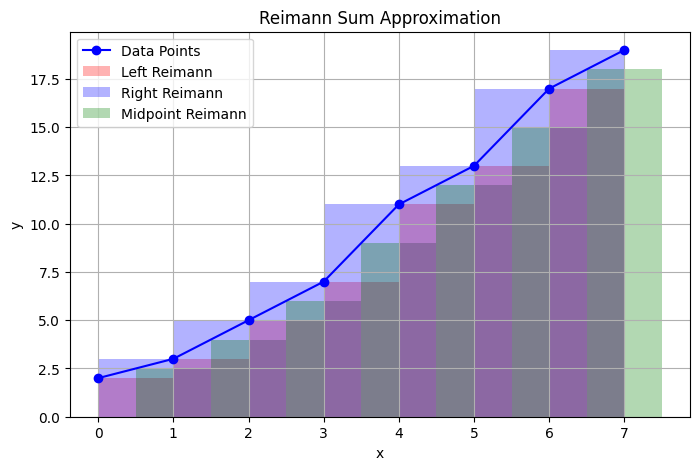

In [41]:
# Visualization
plt.figure(figsize=(8, 5))
plt.plot(x_values, y_values, 'bo-', label='Data Points')
for i in range(len(x_values)-1):
  plt.bar(x_values[i], y_values[i], width=x_values[i+1]-x_values[i], align='edge', alpha=0.3, color='red', label='Left Reimann' if i == 0 else '')
  plt.bar(x_values[i+1], y_values[i+1], width=-(x_values[i+1]-x_values[i]), align='edge', alpha=0.3, color='blue', label='Right Reimann' if i == 0 else '')
  mid_x = (x_values[i] + x_values[i+1]) / 2
  mid_y = (y_values[i] + y_values[i+1]) / 2
  plt.bar(mid_x, mid_y, width=x_values[i+1]-x_values[i], align='edge', alpha=0.3, color='green', label='Midpoint Reimann' if i == 0 else '')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Reimann Sum Approximation')
plt.legend()
plt.grid()
plt.show()